# Plot of the galaxy flux map

In [1]:
# Imports
import ROOT
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 400


In [2]:
# Global variables
dirDir = "/home/users/l/lebrun/"
resultPath = dirDir + "results/"
figPath = dirDir + "figures/"
dataPath = dirDir + "data/"
filename = dataPath + "DmlNtup_Data_8years_FullPhotonData_AllSky.root"
res_n = 1.5 # Resolution of maps : nb of pixels per angular degree

In [3]:
tree = None
f = ROOT.TFile(filename, "READ") 

tree = f.Get("DmlNtup")
print(tree)
print(type(tree))

Name: DmlNtup Title: DmlNtup
<class cppyy.gbl.TTree at 0xadee610>


### Load exposure map

In [4]:


expfilename = f"normalized_exposure_map_n={res_n}.npy"
exposure = np.load(resultPath + expfilename)
print(exposure.shape)

(539, 269)


### Initialize lifetime

In [5]:
lifetime = 1.9182978e8 
print(exposure)
print(np.min(exposure), np.max(exposure))

[[0.00379371 0.00418828 0.00101302 ... 0.00503978 0.00370023 0.00367351]
 [0.00213397 0.00929732 0.00540617 ... 0.01201473 0.0088414  0.0034364 ]
 [0.         0.01024765 0.01559396 ... 0.01234156 0.0100167  0.00259562]
 ...
 [0.00099139 0.01180062 0.00867268 ... 0.01406771 0.01147952 0.00624163]
 [0.00282313 0.00780936 0.00641067 ... 0.00696346 0.00302387 0.00468182]
 [0.00112736 0.01312903 0.01061779 ... 0.01495435 0.00783523 0.00286656]]
0.0 1.0


### Load Acceptance

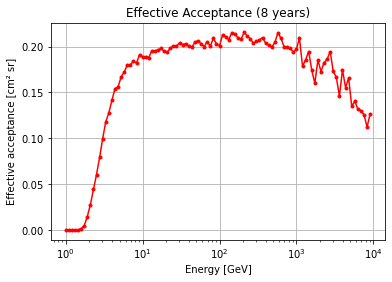

In [6]:
# Load acceptance       
localDataPath = "/home/users/l/lebrun/data/"
acceptance = np.loadtxt(localDataPath+"acceptance_vs_energy_cutBDT_v25.txt") # 100 values

ene = np.logspace(1, 5, 101) / 10 
fig, ax = plt.subplots()
ax.semilogx(ene[:-1], acceptance, "r.-")
ax.set_xlabel("Energy [GeV]")
ax.set_ylabel("Effective acceptance [cm² sr]")
ax.set_title("Effective Acceptance (8 years)")
ax.grid()
fig.savefig(figPath+"acceptance.pdf")

### Interpolate acceptance

In [7]:
from scipy import interpolate

def create_acceptance_function(energy_edges, acceptance_values):
    """
    Creates an interpolation function that returns acceptance values
    for given energy inputs.
    
    Parameters:
    energy_values (array): Array of energy values in log scale
    acceptance_values (array): Array of corresponding acceptance values
    
    Returns:
    function: Interpolation function that takes energy as input and returns acceptance
    """
    # Calculate bin centers (geometric mean for log-spaced bins)
    energy_centers = np.sqrt(energy_edges[:-1] * energy_edges[1:])
    # Create interpolation function
    # We use 'linear' interpolation which works well for log-scaled data
    interp_func = interpolate.interp1d(
        energy_centers,
        acceptance_values,
        kind='linear',
        bounds_error=False,  # Don't raise error for out-of-bounds values
        fill_value=(acceptance_values[0], acceptance_values[-1])  # Extrapolate using edge values
    )
    
    return interp_func

# Create the function
acceptance_function = create_acceptance_function(ene, acceptance)  # Note: ene has 101 values but acceptance has 100

# TEST
energy_centers = np.sqrt(ene[:-1] * ene[1:])
test_energy = np.mean((energy_centers[40], energy_centers[41]))
expected_A = np.mean((acceptance[40], acceptance[41]))
interpolated_acceptance = acceptance_function(test_energy)
print(f"Energy index 40 : {energy_centers[40]}, acceptance {acceptance[40]}")
print(f"Energy index 41 : {energy_centers[41]}, acceptance {acceptance[41]}")
print(f"Acceptance at energy {test_energy} = {interpolated_acceptance} ; expected {expected_A}")

Energy index 40 : 41.68693834703355, acceptance 0.200052645377
Energy index 41 : 45.708818961487495, acceptance 0.199120136823
Acceptance at energy 43.69787865426052 = 0.1995863911 ; expected 0.19958639109999998


### Associate acceptance to every entry

In [8]:
df = ROOT.RDataFrame(tree)
df = df.Filter("tt_bgoTotalE_GeV >= 3")
dfNpy = df.AsNumpy(["tt_bgoTotalE_GeV", "celestialcoordBest_2", "celestialcoordBest_3"])
energies = dfNpy["tt_bgoTotalE_GeV"]
acceptances = acceptance_function(energies)

dfNpy["acceptance"] = acceptances

# Rename + convert coords

dfNpy["energy"] = dfNpy.pop("tt_bgoTotalE_GeV")
dfNpy["longitude"] = dfNpy.pop("celestialcoordBest_2")
dfNpy["longitude"] = -(dfNpy["longitude"] - 2*np.pi*(dfNpy["longitude"]//np.pi))
dfNpy["latitude"] = dfNpy.pop("celestialcoordBest_3")

dfNpy["flux"] = (dfNpy["acceptance"]**(-1))/lifetime

### Create histogram, divide by lifetime and exposure

In [9]:
# Define the edges of the bins for longitude and latitude
lon_bins = np.linspace(-np.pi, np.pi, int(360*res_n))  # Adjust the number of bins as needed
lat_bins = np.linspace(-np.pi/2, np.pi/2, int(180*res_n))

# Create 2D histogram (aggregates energy values)
flux_grid, lon_edges, lat_edges = np.histogram2d(
    dfNpy["longitude"], dfNpy["latitude"], 
    bins=[lon_bins, lat_bins], 
    weights=dfNpy["flux"]
)

print(flux_grid.shape)
print(exposure.shape)

flux_grid_corr = flux_grid.copy()
flux_grid_corr[exposure != 0] = flux_grid[exposure != 0]/exposure[exposure != 0]


(539, 269)
(539, 269)


### Plot non-corrected flux map 

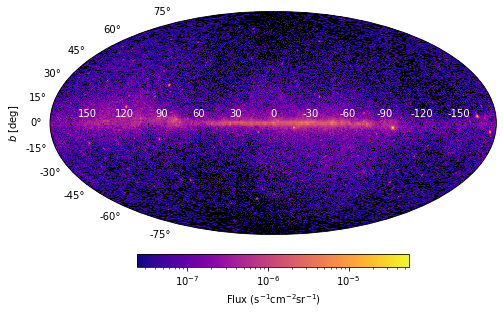

In [10]:
# Création du plot en projection Mollweide
fig1 = plt.figure(figsize=(8, 5))
ax1 = fig1.add_subplot(111, projection="mollweide")
ax1.set_facecolor('black')
# Plot the 2D histogram using pcolormesh
# We use the logarithmic normalization for the color scale
cmap = "plasma"
norm = mcolors.LogNorm()  # Use logarithmic normalization for color scale
pc = ax1.pcolormesh(lon_edges, lat_edges, flux_grid.T, cmap=cmap, norm=norm, shading='auto')

# Colorbar
cbar = fig1.colorbar(pc, ax=ax1, orientation="horizontal", fraction=0.05, pad=0.07)
cbar.set_label(r"Flux (s$^{-1}$cm$^{-2}$sr$^{-1}$)")

# Modifying axis labels and grid
ax1.xaxis.set_tick_params(labelcolor="white")
tick_labels = np.array([150, 120, 90, 60, 30, 0, -30, -60, -90, -120, -150])
ax1.set_xticklabels(tick_labels)
ax1.set_ylabel(r"$b$ [deg]")
# ax1.grid(True, linestyle="-", alpha=0.5)
# Show the plot
plt.show()

### Plot exposure map

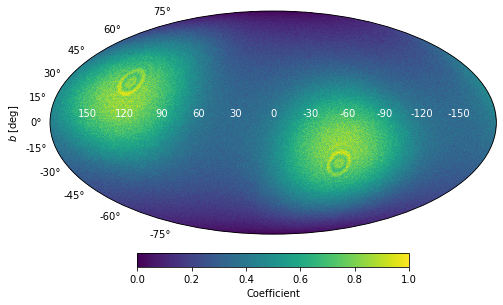

In [11]:
# Création du plot en projection Mollweide
fig2 = plt.figure(figsize=(8, 5))
ax2 = fig2.add_subplot(111, projection="mollweide")
ax2.set_facecolor('black')
# Plot the 2D histogram using pcolormesh
# We use the logarithmic normalization for the color scale
cmap = "viridis"
pc = ax2.pcolormesh(lon_edges, lat_edges, exposure.T, cmap=cmap, shading='auto')

# Colorbar
cbar = fig2.colorbar(pc, ax=ax2, orientation="horizontal", fraction=0.05, pad=0.07)
cbar.set_label(r"Coefficient")

# Modifying axis labels and grid
ax2.xaxis.set_tick_params(labelcolor="white")
tick_labels = np.array([150, 120, 90, 60, 30, 0, -30, -60, -90, -120, -150])
ax2.set_xticklabels(tick_labels)
ax2.set_ylabel(r"$b$ [deg]")
#ax2.grid(True, linestyle="-", alpha=0.5)
# Show the plot
plt.show()

## Plot the map

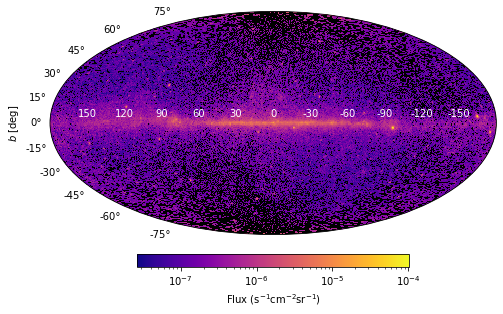

In [13]:
# Création du plot en projection Mollweide
fig3 = plt.figure(figsize=(8, 5))
ax3 = fig3.add_subplot(111, projection="mollweide")
ax3.set_facecolor('black')
# Plot the 2D histogram using pcolormesh
# We use the logarithmic normalization for the color scale
cmap = "plasma"
norm = mcolors.LogNorm()  # Use logarithmic normalization for color scale
pc = ax3.pcolormesh(lon_edges, lat_edges, flux_grid_corr.T, cmap=cmap, norm=norm, shading='auto')

# Colorbar
cbar = fig3.colorbar(pc, ax=ax3, orientation="horizontal", fraction=0.05, pad=0.07)
cbar.set_label(r"Flux (s$^{-1}$cm$^{-2}$sr$^{-1}$)")

# Modifying axis labels and grid
ax3.xaxis.set_tick_params(labelcolor="white")
tick_labels = np.array([150, 120, 90, 60, 30, 0, -30, -60, -90, -120, -150])
ax3.set_xticklabels(tick_labels)
ax3.set_ylabel(r"$b$ [deg]")
#ax3.grid(True, linestyle="-", alpha=0.5)
fig3.savefig(figPath+f"FluxMap_n={res_n}.png")
# Show the plot
plt.show()